# 02 - Baseline Modeling

This notebook establishes the first reproducible machine learning baseline for the
Diabetes 130-US Hospitals dataset.

## Purpose

The goal of this baseline is to:

1. Load the audited dataset.
2. Define the prediction target.
3. Remove variables that should not be used as predictors.
4. Split the data into training and test sets.
5. Build a reproducible preprocessing pipeline.
6. Train baseline classification models.
7. Evaluate predictive performance.
8. Save predicted class probabilities for later uncertainty analysis.

This baseline will serve as the reference point for later experiments involving
controlled missingness and predictive uncertainty.

### Research connection

The broader research question is:

> Does a model's predictive uncertainty increase when important information is
> missing from an EHR record, and can that uncertainty help identify predictions
> that are less reliable?

The uncertainty experiments will be built on top of this baseline rather than
being introduced before establishing conventional model performance.

In [4]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# Path to the project directory
PROJECT_ROOT = "/Users/anshulraghu/Desktop/ehr-uncertainty"

# Path to the dataset
LOCAL_DATA_PATH = os.path.join(
    PROJECT_ROOT,
    "data",
    "raw",
    "diabetic_data.csv"
)

if os.path.exists(LOCAL_DATA_PATH):
    print(f"Loading local dataset from:\n{LOCAL_DATA_PATH}")
    df = pd.read_csv(LOCAL_DATA_PATH)
else:
    print("Local dataset not found.")
    print("Fetching the dataset from UCI instead...")

    diabetes = fetch_ucirepo(id=296)

    X_uci = diabetes.data.features
    y_uci = diabetes.data.targets

    df = pd.concat([X_uci, y_uci], axis=1)

    os.makedirs(os.path.dirname(LOCAL_DATA_PATH), exist_ok=True)
    df.to_csv(LOCAL_DATA_PATH, index=False)

    print(f"Dataset saved to:\n{LOCAL_DATA_PATH}")

print(f"\nDataset shape: {df.shape}")
display(df.head())

Loading local dataset from:
/Users/anshulraghu/Desktop/ehr-uncertainty/data/raw/diabetic_data.csv

Dataset shape: (101766, 48)


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [6]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
display(
    df["readmitted"]
    .value_counts()
    .rename_axis("readmitted")
    .reset_index(name="count")
)

print("\nTarget proportions:")
display(
    df["readmitted"]
    .value_counts(normalize=True)
    .round(4)
    .rename_axis("readmitted")
    .reset_index(name="proportion")
)

Dataset shape: (101766, 48)

Target distribution:


,readmitted,count
0,NO,54864
1,>30,35545
2,<30,11357



Target proportions:


,readmitted,proportion
0,NO,0.5391
1,>30,0.3493
2,<30,0.1116


## 1. Define the Prediction Task

The target is the three-class `readmitted` variable:

- `NO` — the patient was not readmitted within 30 days
- `>30` — the patient was readmitted after 30 days
- `<30` — the patient was readmitted within 30 days

For this initial baseline, the task is treated as a three-class classification
problem.

The baseline intentionally focuses on establishing a reproducible prediction
pipeline before introducing controlled missingness and uncertainty estimation.

In [7]:
TARGET = "readmitted"

# Identifiers should not be treated as meaningful clinical predictors.
IDENTIFIER_COLUMNS = [
    "encounter_id",
    "patient_nbr",
]

X = df.drop(columns=[TARGET] + IDENTIFIER_COLUMNS, errors="ignore")
y = df[TARGET].copy()

print("Target:", TARGET)

print("\nRemoved identifier columns:")
for column in IDENTIFIER_COLUMNS:
    if column in df.columns:
        print(f"  - {column}")

print(f"\nPredictor shape: {X.shape}")
print(f"Target shape:    {y.shape}")

Target: readmitted

Removed identifier columns:

Predictor shape: (101766, 47)
Target shape:    (101766,)


In [8]:
duplicate_count = X.duplicated().sum()

print(f"Duplicate predictor rows: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_count / len(X) * 100:.2f}%")

Duplicate predictor rows: 0
Duplicate percentage: 0.00%


## 2. Train/Test Split

A stratified train/test split is used so that the class proportions are approximately preserved in both sets.

The test set is held out from model fitting and preprocessing parameter estimation. This is important because later uncertainty experiments will also
need an evaluation set that the model has not seen during training.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).round(4))

print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).round(4))

Training set: (81412, 47)
Test set:     (20354, 47)

Training target proportions:


readmitted
NO     0.5391
>30    0.3493
<30    0.1116
Name: proportion, dtype: float64


Test target proportions:


readmitted
NO     0.5391
>30    0.3493
<30    0.1116
Name: proportion, dtype: float64

In [10]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print(f"Numeric features:     {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")

print("\nNumeric features:")
print(numeric_features)

print("\nFirst categorical features:")
print(categorical_features[:30])

Numeric features:     11
Categorical features: 36

Numeric features:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

First categorical features:
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin']


## 3. Preprocessing

The baseline uses separate preprocessing for numerical and categorical variables.

### Numerical variables

Missing numerical values are replaced using the median calculated from the
training data.

Numerical features are then standardized for logistic regression.

### Categorical variables

Missing categorical values are replaced with the most frequent category.
Categorical variables are then one-hot encoded.

All preprocessing is placed inside a scikit-learn pipeline so that statistics
used for imputation and encoding are learned only from the training data.

In [11]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 4. Baseline Model 1 — Multinomial Logistic Regression

Logistic regression provides a relatively simple and interpretable baseline.

Importantly for this project, it also produces class probabilities. These
probabilities will be useful later when examining predictive confidence and
uncertainty under different missing-data conditions.

In [12]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                solver="saga",
                random_state=42
            ),
        ),
    ]
)

print("Training logistic regression...")

logistic_model.fit(X_train, y_train)

print("Training complete.")

Training logistic regression...
Training complete.


In [13]:
y_pred_logistic = logistic_model.predict(X_test)
y_proba_logistic = logistic_model.predict_proba(X_test)

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred_logistic
)
logistic_macro_f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="macro"
)
logistic_log_loss = log_loss(
    y_test,
    y_proba_logistic,
    labels=logistic_model.classes_
)

print("Logistic Regression Results")
print("=" * 40)
print(f"Accuracy:            {logistic_accuracy:.4f}")
print(f"Balanced Accuracy:   {logistic_balanced_accuracy:.4f}")
print(f"Macro F1:             {logistic_macro_f1:.4f}")
print(f"Log Loss:             {logistic_log_loss:.4f}")

Logistic Regression Results
Accuracy:            0.5763
Balanced Accuracy:   0.4011
Macro F1:             0.3811
Log Loss:             0.8971


In [14]:
print("Classification Report — Logistic Regression")
print()

print(
    classification_report(
        y_test,
        y_pred_logistic,
        digits=4
    )
)

Classification Report — Logistic Regression

              precision    recall  f1-score   support

         <30     0.3261    0.0198    0.0373      2272
         >30     0.4962    0.3369    0.4013      7109
          NO     0.6036    0.8465    0.7047     10973

    accuracy                         0.5763     20354
   macro avg     0.4753    0.4011    0.3811     20354
weighted avg     0.5351    0.5763    0.5243     20354



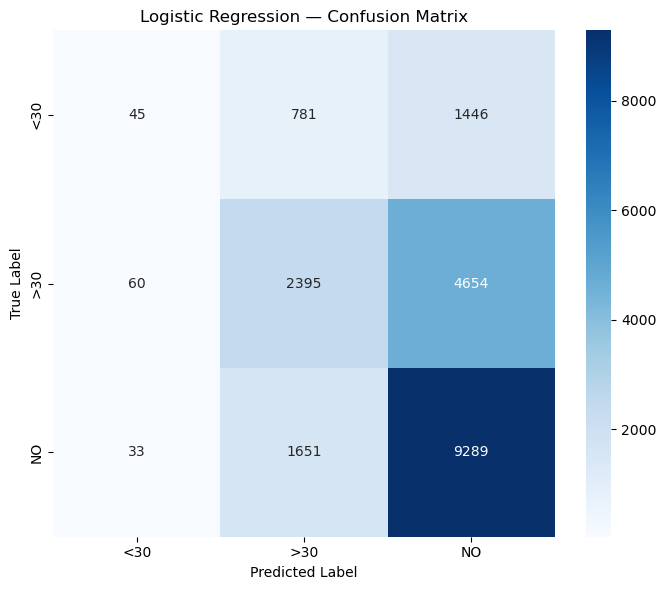

In [15]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=logistic_model.classes_
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

### Why use multiple metrics?

The target classes are imbalanced, with `NO` representing the largest class.

Therefore, accuracy by itself can hide poor performance on less frequent
classes, particularly the `<30` class.

For this reason, the baseline reports:

- Accuracy
- Balanced accuracy
- Macro F1
- Log loss

Log loss is especially useful for this project because it evaluates the quality
of the model's predicted probabilities, which will become important when
studying predictive uncertainty.

## 5. Baseline Model 2 — Random Forest

A random forest provides a second baseline with a nonlinear model family.

Comparing a relatively simple linear model with a tree-based model gives a
better reference point before introducing uncertainty-focused experiments.

In [16]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ),
        ),
    ]
)

print("Training random forest...")

random_forest_model.fit(X_train, y_train)

print("Training complete.")

Training random forest...
Training complete.


In [17]:
y_pred_rf = random_forest_model.predict(X_test)
y_proba_rf = random_forest_model.predict_proba(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred_rf
)
rf_macro_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="macro"
)
rf_log_loss = log_loss(
    y_test,
    y_proba_rf,
    labels=random_forest_model.classes_
)

print("Random Forest Results")
print("=" * 40)
print(f"Accuracy:            {rf_accuracy:.4f}")
print(f"Balanced Accuracy:   {rf_balanced_accuracy:.4f}")
print(f"Macro F1:             {rf_macro_f1:.4f}")
print(f"Log Loss:             {rf_log_loss:.4f}")

Random Forest Results
Accuracy:            0.5056
Balanced Accuracy:   0.4586
Macro F1:             0.4372
Log Loss:             1.0400


In [18]:
print("Classification Report — Random Forest")
print()

print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=4
    )
)

Classification Report — Random Forest

              precision    recall  f1-score   support

         <30     0.1932    0.3900    0.2584      2272
         >30     0.4680    0.3657    0.4106      7109
          NO     0.6665    0.6202    0.6425     10973

    accuracy                         0.5056     20354
   macro avg     0.4425    0.4586    0.4372     20354
weighted avg     0.5443    0.5056    0.5186     20354



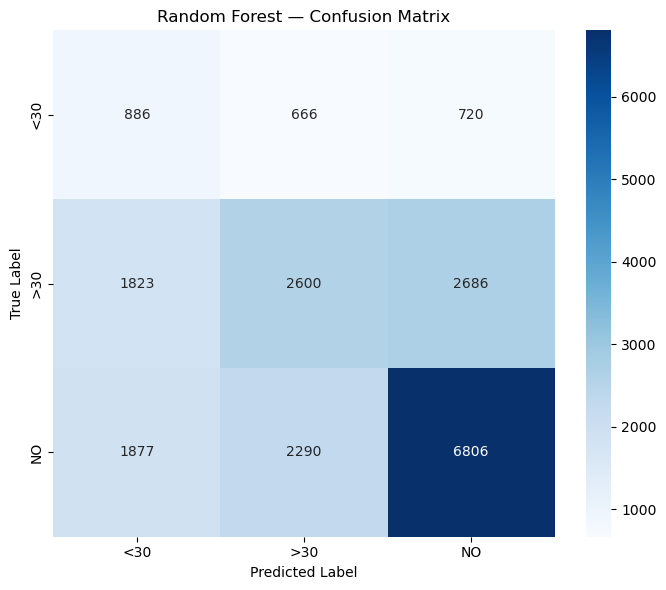

In [19]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=random_forest_model.classes_
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=random_forest_model.classes_,
    yticklabels=random_forest_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

In [20]:
results = pd.DataFrame(
    {
        "Model": [
            "Logistic Regression",
            "Random Forest",
        ],
        "Accuracy": [
            logistic_accuracy,
            rf_accuracy,
        ],
        "Balanced Accuracy": [
            logistic_balanced_accuracy,
            rf_balanced_accuracy,
        ],
        "Macro F1": [
            logistic_macro_f1,
            rf_macro_f1,
        ],
        "Log Loss": [
            logistic_log_loss,
            rf_log_loss,
        ],
    }
)

results = results.round(4)

display(results)

,Model,Accuracy,Balanced Accuracy,Macro F1,Log Loss
0,Logistic Regression,0.5763,0.4011,0.3811,0.8971
1,Random Forest,0.5056,0.4586,0.4372,1.0400


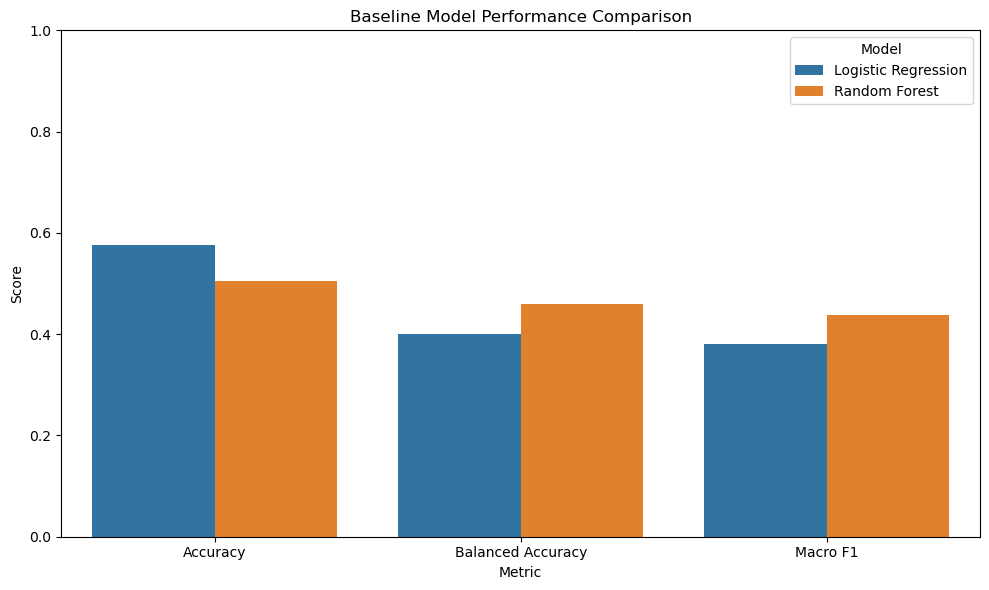

In [21]:
metrics_to_plot = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
]

results_plot = results.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Baseline Model Performance Comparison")
plt.tight_layout()
plt.show()

## 6. Predictive Probabilities

The models provide a probability distribution across the three possible
readmission classes.

For example, a prediction might look like:

`NO: 0.80, >30: 0.15, <30: 0.05`

while another might look like:

`NO: 0.36, >30: 0.34, <30: 0.30`

The first prediction is relatively confident, while the second is much more
ambiguous.

These probabilities provide the starting point for later predictive
uncertainty analysis.

In [22]:
probability_df = pd.DataFrame(
    y_proba_logistic,
    columns=[
        f"prob_{class_name}"
        for class_name in logistic_model.classes_
    ],
    index=y_test.index
)

probability_df["true_label"] = y_test
probability_df["predicted_label"] = y_pred_logistic

probability_df["confidence"] = probability_df[
    [f"prob_{class_name}" for class_name in logistic_model.classes_]
].max(axis=1)

display(probability_df.head(10))

,prob_<30,prob_>30,prob_NO,true_label,predicted_label,confidence
8705,0.080621,0.400416,0.518962,NO,NO,0.518962
31602,0.074553,0.462095,0.463352,<30,NO,0.463352
100564,0.109018,0.330241,0.560741,NO,NO,0.560741
19157,0.043202,0.287667,0.669131,NO,NO,0.669131
59372,0.113030,0.554338,0.332632,>30,>30,0.554338
90164,0.085619,0.252735,0.661646,NO,NO,0.661646
19028,0.071699,0.353939,0.574362,NO,NO,0.574362
59483,0.191279,0.390478,0.418243,>30,NO,0.418243
85060,0.124062,0.331212,0.544726,>30,NO,0.544726
97711,0.070438,0.300715,0.628847,NO,NO,0.628847


In [23]:
print("Confidence summary:")
display(
    probability_df["confidence"].describe()
)

Confidence summary:


count    20354.000000
mean         0.588182
std          0.107777
min          0.342498
25%          0.501896
50%          0.574895
75%          0.661157
max          0.978740
Name: confidence, dtype: float64

In [24]:
probability_df["correct"] = (
    probability_df["true_label"]
    == probability_df["predicted_label"]
)

print("Average confidence by prediction correctness:")

display(
    probability_df
    .groupby("correct")["confidence"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

Average confidence by prediction correctness:


,count,mean,median,std
correct,,,,
False,8625,0.5631,0.5474,0.0974
True,11729,0.6067,0.5968,0.1112


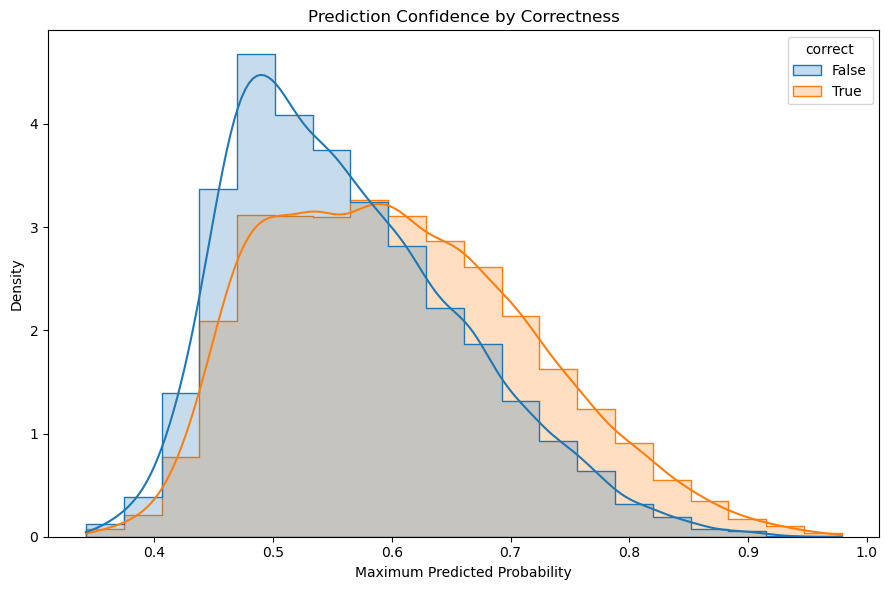

In [25]:
plt.figure(figsize=(9, 6))

sns.histplot(
    data=probability_df,
    x="confidence",
    hue="correct",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlabel("Maximum Predicted Probability")
plt.ylabel("Density")
plt.title("Prediction Confidence by Correctness")
plt.tight_layout()
plt.show()

In [26]:
most_uncertain = (
    probability_df
    .sort_values("confidence")
    .head(10)
)

display(most_uncertain)

,prob_<30,prob_>30,prob_NO,true_label,predicted_label,confidence,correct
21736,0.334609,0.342498,0.322893,NO,>30,0.342498,False
11551,0.336602,0.342965,0.320433,NO,>30,0.342965,False
91477,0.341485,0.315194,0.343321,NO,NO,0.343321,True
16320,0.337641,0.318015,0.344344,NO,NO,0.344344,True
71778,0.330174,0.345571,0.324255,>30,>30,0.345571,True
76296,0.315668,0.338695,0.345637,NO,NO,0.345637,True
100669,0.313831,0.347111,0.339058,NO,>30,0.347111,False
74886,0.341205,0.305847,0.352947,NO,NO,0.352947,True
41906,0.323071,0.353587,0.323342,NO,>30,0.353587,False
48095,0.320766,0.325412,0.353822,NO,NO,0.353822,True


## 7. Save Baseline Outputs

The baseline predictions are saved so that later notebooks can reuse the
results without retraining the models unnecessarily.

The saved probabilities will also provide a reference for comparing model
confidence under controlled missingness.

In [27]:
OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

baseline_predictions = probability_df.copy()

baseline_predictions.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "baseline_logistic_predictions.csv"
    )
)

results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "baseline_model_results.csv"
    ),
    index=False
)

print("Saved:")
print(
    os.path.join(
        OUTPUT_DIR,
        "baseline_logistic_predictions.csv"
    )
)
print(
    os.path.join(
        OUTPUT_DIR,
        "baseline_model_results.csv"
    )
)

Saved:
/Users/anshulraghu/Desktop/ehr-uncertainty/data/processed/baseline_logistic_predictions.csv
/Users/anshulraghu/Desktop/ehr-uncertainty/data/processed/baseline_model_results.csv


## 8. Baseline Conclusions

### What was established?

This notebook established a reproducible baseline classification pipeline for
the Diabetes 130-US Hospitals dataset.

The pipeline:

1. Loads the UCI dataset.
2. Separates predictors and the `readmitted` target.
3. Removes identifier variables.
4. Uses a stratified train/test split.
5. Handles missing numerical and categorical values within the training
   pipeline.
6. Encodes categorical variables.
7. Trains logistic regression and random forest models.
8. Evaluates accuracy, balanced accuracy, macro F1, and log loss.
9. Produces class probabilities that can be used for later uncertainty
   analysis.

### What has not been established yet?

This baseline does **not** yet answer the main research question.

In particular, the notebook has not yet:

- introduced controlled missingness,
- determined which missingness patterns are most important,
- compared prediction uncertainty under different missingness levels,
- calibrated the model's probabilities,
- or established whether uncertainty can reliably identify incorrect
  predictions.

Those experiments will build on this baseline.

## 9. Next Steps

The next experimental stage will introduce controlled missingness into the
evaluation data and compare model behavior under different information
conditions.

The planned progression is:

**Complete baseline**
→ **Controlled missingness**
→ **Prediction performance**
→ **Predictive uncertainty**
→ **Calibration / reliability analysis**

The central question will be whether removing important information causes
predictive uncertainty to increase and whether higher uncertainty is associated
with a greater likelihood of prediction error.